In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("dataset/StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.shape

(1000, 8)

In [4]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [6]:
df.dtypes

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

In [7]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [8]:
df.shape

(1000, 8)

In [9]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [11]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [12]:
## 5-Line Dataset Summary

1. The dataset contains 1000 student records and 8 columns.
2. It includes demographic information such as gender and race/ethnicity.
3. It contains parental education level, lunch type, and test preparation information.
4. Student academic performance is measured using math, reading, and writing scores.
5. The dataset contains no missing values, so it is ready for further analysis.

SyntaxError: invalid syntax (2184070327.py, line 3)

In [13]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique())


 gender
['female' 'male']

 race/ethnicity
['group B' 'group C' 'group A' 'group D' 'group E']

 parental level of education
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

 lunch
['standard' 'free/reduced']

 test preparation course
['none' 'completed']

 math score
[ 72  69  90  47  76  71  88  40  64  38  58  65  78  50  18  46  54  66
  44  74  73  67  70  62  63  56  97  81  75  57  55  53  59  82  77  33
  52   0  79  39  45  60  61  41  49  30  80  42  27  43  68  85  98  87
  51  99  84  91  83  89  22 100  96  94  48  35  34  86  92  37  28  24
  26  95  36  29  32  93  19  23   8]

 reading score
[ 72  90  95  57  78  83  43  64  60  54  52  81  53  75  89  32  42  58
  69  73  71  74  70  65  87  56  61  84  55  44  41  85  59  17  39  80
  37  63  51  49  26  68  45  47  86  34  79  66  67  91 100  76  77  82
  92  93  62  88  50  28  48  46  23  38  94  97  99  31  96  24  29  40]

 writing score
[ 74  88  93 

In [14]:
df["total score"] = df["math score"] + df["reading score"] + df["writing score"]

df[["math score", "reading score", "writing score", "total score"]].head()

,math score,reading score,writing score,total score
0,72,72,74,218
1,69,90,88,247
2,90,95,93,278
3,47,57,44,148
4,76,78,75,229


In [15]:
parental_scores = df.groupby("parental level of education")[
    ["math score", "reading score", "writing score", "total score"]
].mean().round(2)

parental_scores

,math score,reading score,writing score,total score
parental level of education,,,,
associate's degree,67.88,70.93,69.90,208.71
bachelor's degree,69.39,73.00,73.38,215.77
high school,62.14,64.70,62.45,189.29
master's degree,69.75,75.37,75.68,220.80
some college,67.13,69.46,68.84,205.43
some high school,63.50,66.94,64.89,195.32


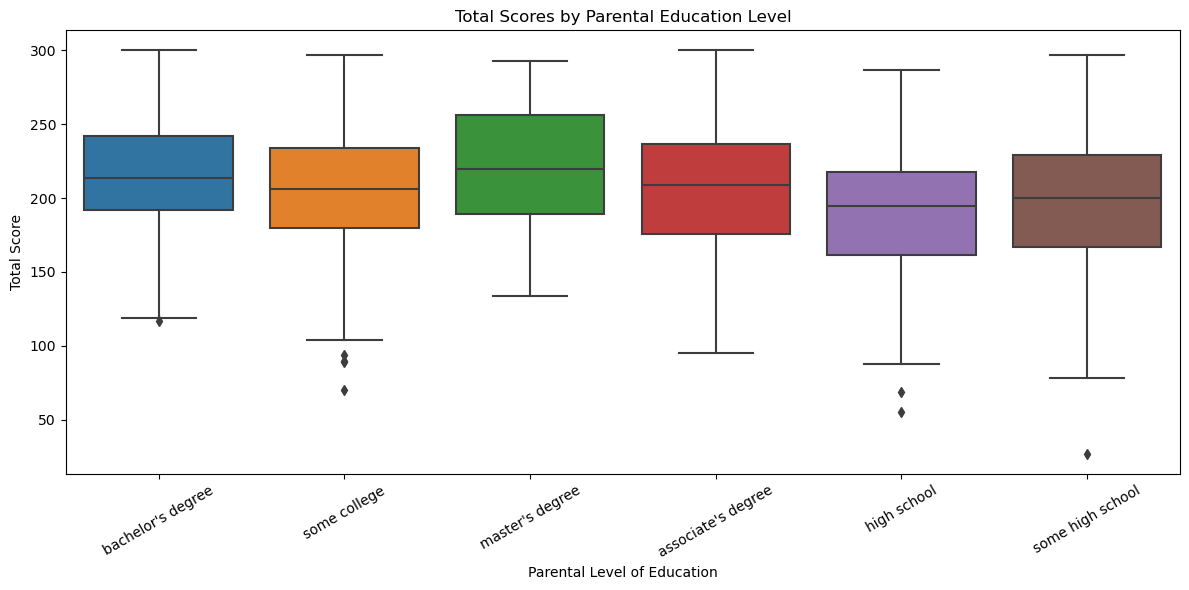

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="parental level of education",
    y="total score"
)

plt.title("Total Scores by Parental Education Level")
plt.xlabel("Parental Level of Education")
plt.ylabel("Total Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [17]:
test_prep_scores = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score", "total score"]
].mean().round(2)

test_prep_scores

,math score,reading score,writing score,total score
test preparation course,,,,
completed,69.70,73.89,74.42,218.01
none,64.08,66.53,64.50,195.12


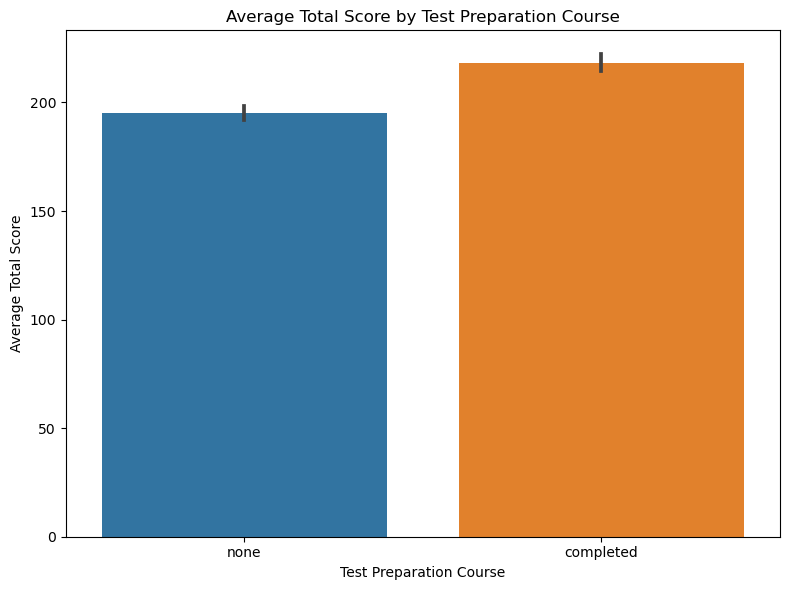

In [18]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="test preparation course",
    y="total score"
)

plt.title("Average Total Score by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Total Score")
plt.tight_layout()
plt.show()

In [19]:
completed = test_prep_scores.loc["completed", "total score"]
none = test_prep_scores.loc["none", "total score"]

difference = completed - none

print("Average score of students who completed test preparation:", completed)
print("Average score of students who did not complete test preparation:", none)
print("Difference:", round(difference, 2))

Average score of students who completed test preparation: 218.01
Average score of students who did not complete test preparation: 195.12
Difference: 22.89


In [20]:
correlation = df[["math score", "reading score", "writing score"]].corr().round(2)

correlation

,math score,reading score,writing score
math score,1.00,0.82,0.80
reading score,0.82,1.00,0.95
writing score,0.80,0.95,1.00


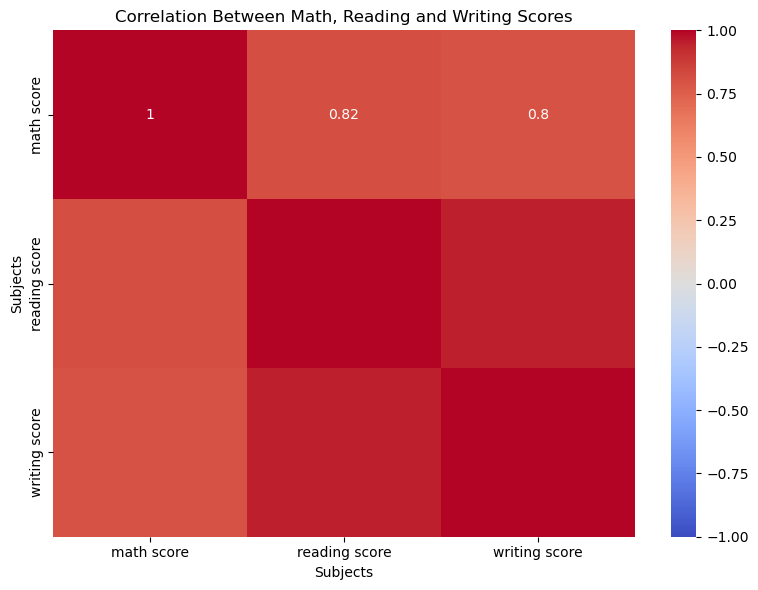

In [21]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Math, Reading and Writing Scores")
plt.xlabel("Subjects")
plt.ylabel("Subjects")
plt.tight_layout()
plt.show()

In [22]:
corr_pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

corr_pairs.stack().sort_values(ascending=False)

reading score  writing score    0.95
math score     reading score    0.82
               writing score    0.80
dtype: float64

In [23]:
gender_scores = df.groupby("gender")[
    ["math score", "reading score", "writing score"]
].mean().round(2)

gender_scores

,math score,reading score,writing score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


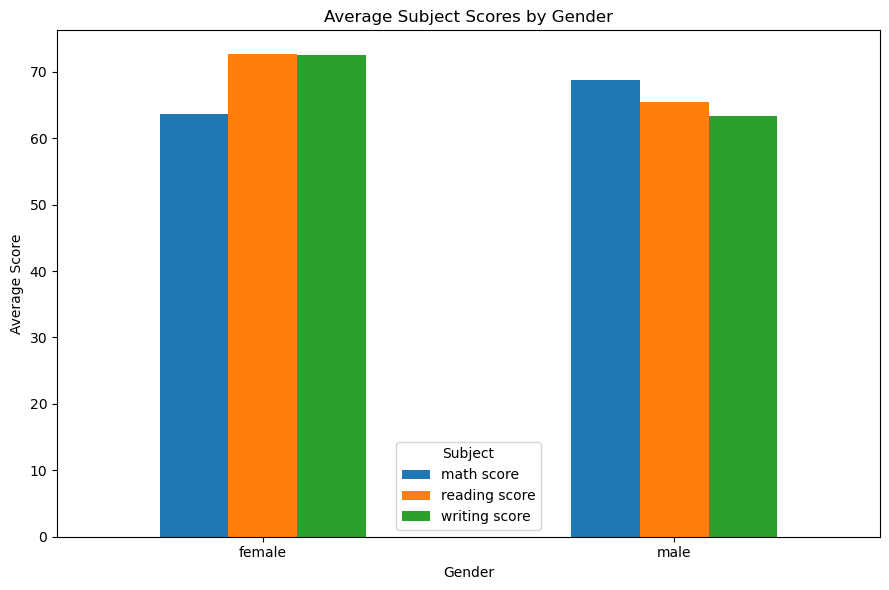

In [24]:
gender_scores.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Average Subject Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

In [25]:
for subject in gender_scores.columns:
    highest_gender = gender_scores[subject].idxmax()
    highest_score = gender_scores[subject].max()
    print(
        subject,
        "->",
        highest_gender,
        "with average score:",
        highest_score
    )

math score -> male with average score: 68.73
reading score -> female with average score: 72.61
writing score -> female with average score: 72.47


In [26]:
df["total score"].describe()

count    1000.000000
mean      203.312000
std        42.771978
min        27.000000
25%       175.000000
50%       205.000000
75%       233.000000
max       300.000000
Name: total score, dtype: float64

C:\Users\Hemalatha S\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


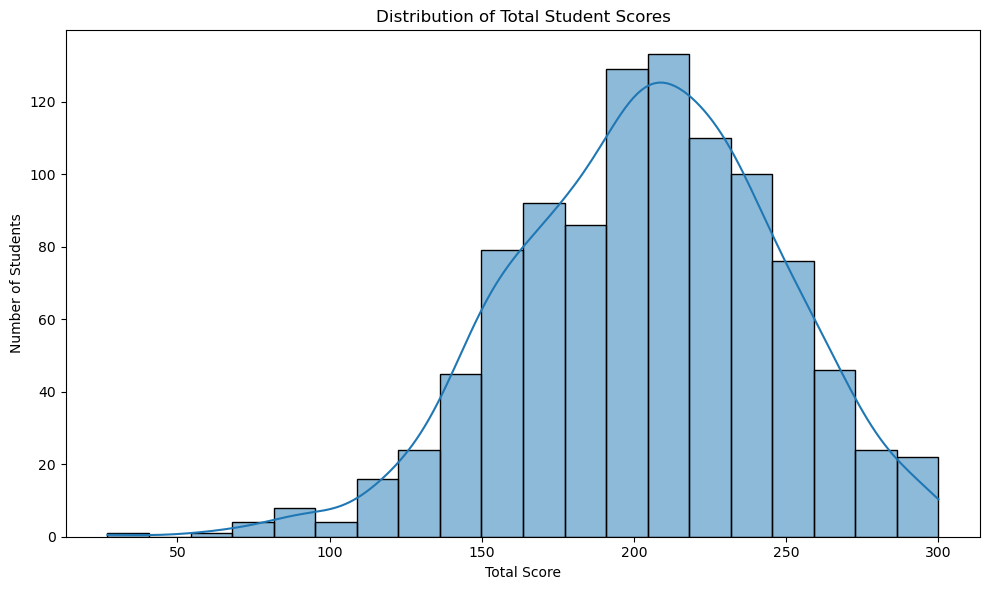

In [27]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="total score",
    bins=20,
    kde=True
)

plt.title("Distribution of Total Student Scores")
plt.xlabel("Total Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [28]:
print("Mean Total Score:", round(df["total score"].mean(), 2))
print("Median Total Score:", df["total score"].median())
print("Minimum Total Score:", df["total score"].min())
print("Maximum Total Score:", df["total score"].max())

Mean Total Score: 203.31
Median Total Score: 205.0
Minimum Total Score: 27
Maximum Total Score: 300


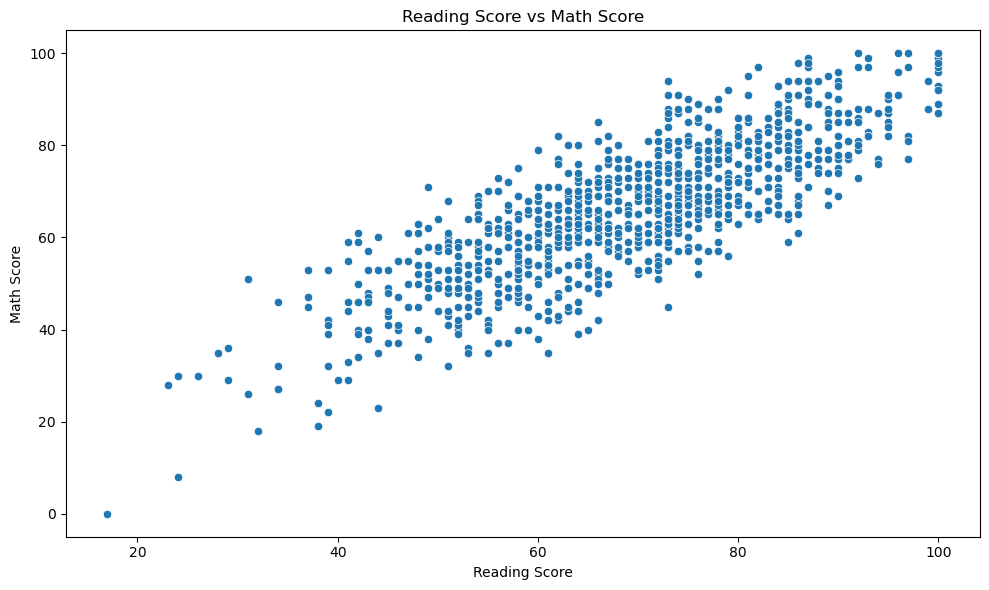

In [29]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="reading score",
    y="math score"
)

plt.title("Reading Score vs Math Score")
plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()

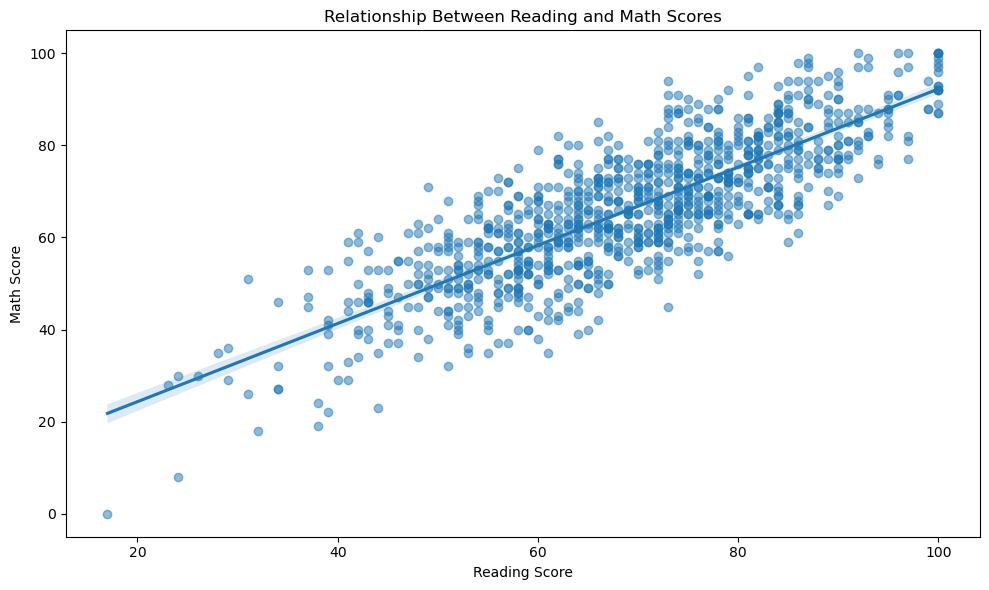

In [30]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="reading score",
    y="math score",
    scatter_kws={"alpha": 0.5}
)

plt.title("Relationship Between Reading and Math Scores")
plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()

In [31]:
df["at_risk"] = (
    (df["math score"] < 50) |
    (df["reading score"] < 50) |
    (df["writing score"] < 50)
)

df["at_risk"].value_counts()

at_risk
False    812
True     188
Name: count, dtype: int64

In [32]:
at_risk_count = df["at_risk"].sum()
total_students = len(df)
at_risk_percentage = (at_risk_count / total_students) * 100

print("Total Students:", total_students)
print("At-Risk Students:", at_risk_count)
print("At-Risk Percentage:", round(at_risk_percentage, 2), "%")


Total Students: 1000
At-Risk Students: 188
At-Risk Percentage: 18.8 %


In [33]:
at_risk_table = pd.DataFrame({
    "Status": ["At-Risk", "Not At-Risk"],
    "Number of Students": [
        df["at_risk"].sum(),
        (~df["at_risk"]).sum()
    ]
})

at_risk_table["Percentage"] = (
    at_risk_table["Number of Students"] / len(df) * 100
).round(2)

at_risk_table

,Status,Number of Students,Percentage
0,At-Risk,188,18.8
1,Not At-Risk,812,81.2


In [34]:
risk_by_gender = (
    df.groupby("gender")["at_risk"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="At-Risk Percentage")
)

risk_by_gender

,gender,At-Risk Percentage
0,female,17.18
1,male,20.54


In [36]:
risk_by_gender = (
    df.groupby("gender")["at_risk"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="At-Risk Percentage")
)

risk_by_gender

,gender,At-Risk Percentage
0,female,17.18
1,male,20.54


In [38]:
risk_by_education = (
    df.groupby("parental level of education")["at_risk"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .reset_index(name="At-Risk Percentage")
)

risk_by_education

,parental level of education,At-Risk Percentage
0,some high school,25.70
1,high school,25.00
2,some college,16.81
3,associate's degree,14.86
4,bachelor's degree,13.56
5,master's degree,10.17


In [39]:
risk_by_gender = (
    df.groupby("gender")["at_risk"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="At-Risk Percentage")
)

risk_by_gender

,gender,At-Risk Percentage
0,female,17.18
1,male,20.54


In [40]:
risk_by_prep = (
    df.groupby("test preparation course")["at_risk"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="At-Risk Percentage")
)

risk_by_prep

,test preparation course,At-Risk Percentage
0,completed,10.06
1,none,23.68


In [41]:
at_risk_table

,Status,Number of Students,Percentage
0,At-Risk,188,18.8
1,Not At-Risk,812,81.2


In [42]:
at_risk_summary = pd.DataFrame({
    "Metric": [
        "Total Students",
        "At-Risk Students",
        "Not At-Risk Students",
        "At-Risk Percentage"
    ],
    "Value": [
        len(df),
        df["at_risk"].sum(),
        (~df["at_risk"]).sum(),
        round(df["at_risk"].mean() * 100, 2)
    ]
})

at_risk_summary

,Metric,Value
0,Total Students,1000.0
1,At-Risk Students,188.0
2,Not At-Risk Students,812.0
3,At-Risk Percentage,18.8


In [43]:
subject_risk = pd.DataFrame({
    "Subject": ["Math", "Reading", "Writing"],
    "Students Below 50": [
        (df["math score"] < 50).sum(),
        (df["reading score"] < 50).sum(),
        (df["writing score"] < 50).sum()
    ]
})

subject_risk["Percentage"] = (
    subject_risk["Students Below 50"] / len(df) * 100
).round(2)

subject_risk

,Subject,Students Below 50,Percentage
0,Math,135,13.5
1,Reading,90,9.0
2,Writing,114,11.4


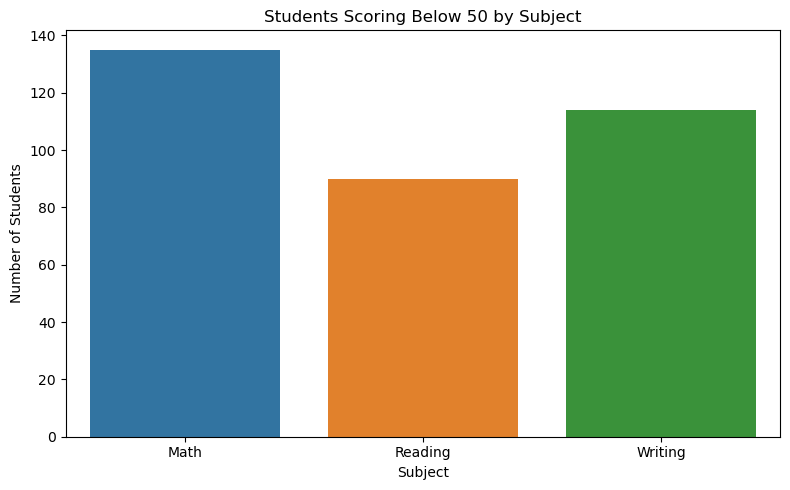

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=subject_risk,
    x="Subject",
    y="Students Below 50"
)

plt.title("Students Scoring Below 50 by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [45]:
## At-Risk Student Analysis
plt.savefig("visualizations/parental_education.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

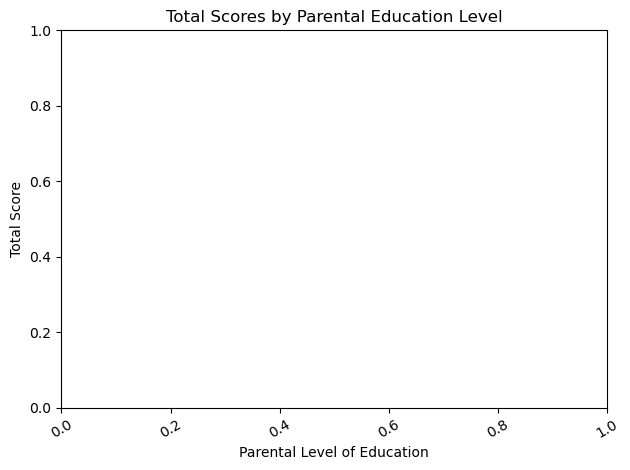

In [46]:
plt.title("Total Scores by Parental Education Level")
plt.xlabel("Parental Level of Education")
plt.ylabel("Total Score")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("visualizations/parental_education.png", dpi=300, bbox_inches="tight")

plt.show()

In [47]:
plt.savefig("visualizations/test_preparation.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [48]:
plt.savefig("visualizations/correlation_heatmap.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [49]:
plt.savefig("visualizations/gender_subject.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [50]:
plt.savefig("visualizations/total_score_distribution.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [51]:
plt.savefig("visualizations/reading_math_scatter.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [52]:
plt.savefig("visualizations/subject_risk.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

# Principal's Report — Student Performance Analysis

## Executive Summary

The analysis of 1,000 student records examined academic scores in mathematics, reading, and writing along with demographic and educational factors. Overall, 188 students (18.8%) were identified as at-risk because they scored below 50 in at least one subject. The results indicate differences in performance and at-risk percentages across test preparation, parental education, gender, and subject areas, providing areas where the school can focus additional academic support.

## Key Findings

1. **At-risk students:** 188 out of 1,000 students (18.8%) were identified as at-risk.

2. **Test preparation:** Students who completed the test preparation course had an observed at-risk percentage of 10.06%, compared with 23.68% among students who did not complete it.

3. **Parental education:** The highest observed at-risk percentage was among students whose parents had some high school education (25.70%), while the lowest was among students whose parents had a master's degree (10.17%).

4. **Subject performance:** Mathematics had the highest number of students scoring below 50 (13.5%), followed by writing (11.4%) and reading (9.0%).

5. **Gender:** The observed at-risk percentage was 20.54% for male students and 17.18% for female students.

## Actionable Recommendations

### 1. Strengthen Mathematics Support

Provide targeted mathematics support sessions, additional practice exercises, and regular weekly assessments for students who show difficulty in mathematics.

### 2. Expand Test Preparation Support

Provide structured test-preparation sessions, practice tests, revision materials, and study guidance to help students prepare more effectively for examinations.

### 3. Introduce Early Academic Monitoring

Identify students who score below the academic threshold at an early stage and provide tutoring, mentoring, and appropriate learning resources before performance declines further.

## Most Impactful Recommendation

Expanding structured test-preparation support is a practical area for further investigation because students who completed test preparation had a lower observed at-risk percentage (10.06%) than students who did not complete it (23.68%). The analysis shows an association rather than proof that test preparation directly caused the difference. The school can therefore pilot additional test-preparation support and monitor student performance over time to evaluate its impact.
